IZABELA BARGIEŁ
# AI-BASE FORCASTING OF COMPLEX TIMESERIES


This project compares 3 different aproaches to modeling time series - naive, linear and neural network. All the models were implemented using autoregression (AR) and AR with exagenous variables. The dataset contains of Alphabet stock prices between 2010 and 2026 as well as basic market drivers like S&P 500 or gold price.

AGENDA


*   Data preprocessing
*   Models
* Summary



#DATA PREPROCESSING
* Dataset: Alphabet
* Droped text columns
* Changed negative numbers to NAN
* KNN


In [170]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [171]:
import pandas as pd

file_path = '/content/drive/MyDrive/SZEREGI/PROJEKT/CaseStudy_GOOGL.csv'

df = pd.read_csv(file_path, parse_dates=['date'])
df = df.set_index('date')

In [188]:
from sklearn.impute import KNNImputer
import pandas as pd
import numpy as np


print("Missing values:")
print(df.isna().sum())
print()

# we keep only numeric
df_numeric = df.select_dtypes(include=[np.number]).copy()

# no attribute can be negative
df_numeric[df_numeric < 0] = np.nan

print("Missing values after changing negative to NaN:")
print(df_numeric.isna().sum())
print()

knn_imputer = KNNImputer(n_neighbors=5)
imputed_values = knn_imputer.fit_transform(df_numeric)


df_final = pd.DataFrame(imputed_values, index=df_numeric.index, columns=df_numeric.columns)

# OPTIONAL
df_final = df_final.iloc[:int(len(df_final) * 0.5)]

print("Missing values after KNN:")
print(df_final.isna().sum())

print(f"\nReady dataset:")
display(df_final.head())


print()
print(f"Size of the df: {len(df_final)}")


Missing values:
time         0
symbol       0
volume       0
adjprice     0
oil          0
gold         0
sp500        0
vix          0
rates_10y    0
dtype: int64

Missing values after changing negative to NaN:
time         0
volume       0
adjprice     0
oil          3
gold         3
sp500        0
vix          0
rates_10y    2
dtype: int64

Missing values after KNN:
time         0
volume       0
adjprice     0
oil          0
gold         0
sp500        0
vix          0
rates_10y    0
dtype: int64

Ready dataset:


,time,volume,adjprice,oil,gold,sp500,vix,rates_10y
date,,,,,,,,
2010-01-04,1.0,78169752.0,15.555864,81.510002,1117.699951,1132.989990,20.040001,3.841
2010-01-05,2.0,120067812.0,15.487362,81.769997,1118.099976,1136.520020,19.350000,3.755
2010-01-06,3.0,158988852.0,15.096946,83.180000,1135.900024,1137.140015,19.160000,3.808
2010-01-07,4.0,256315428.0,14.745495,82.660004,1133.099976,1141.689941,19.059999,3.822
2010-01-08,5.0,188783028.0,14.942070,82.750000,1138.199951,1144.979980,18.129999,3.808



Size of the df: 2012


Some visualisations

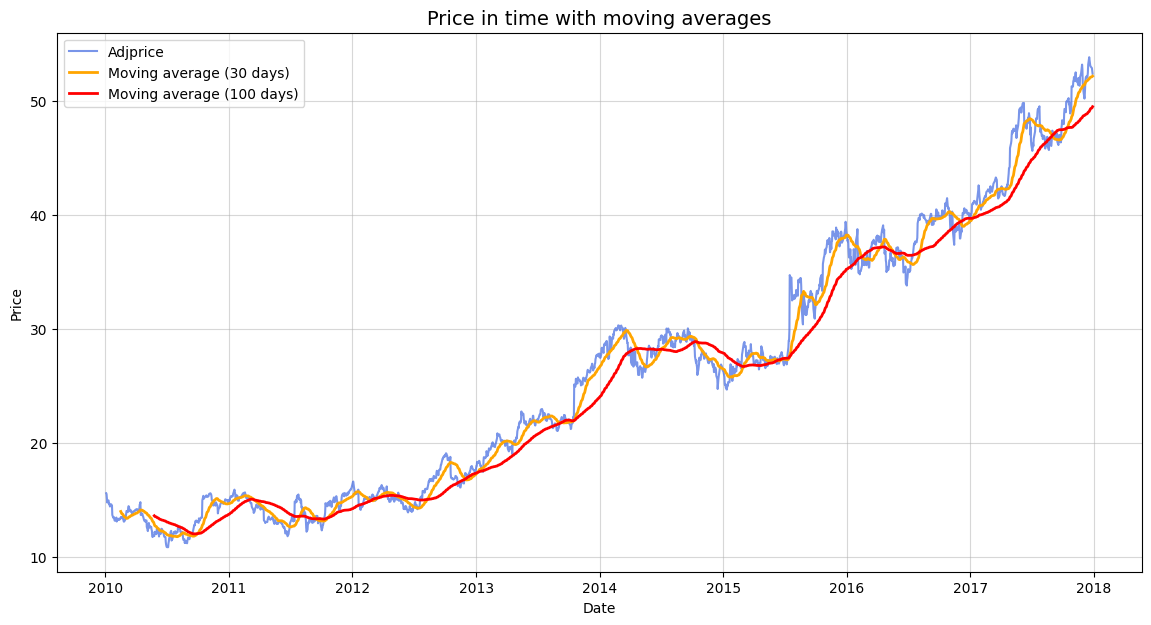

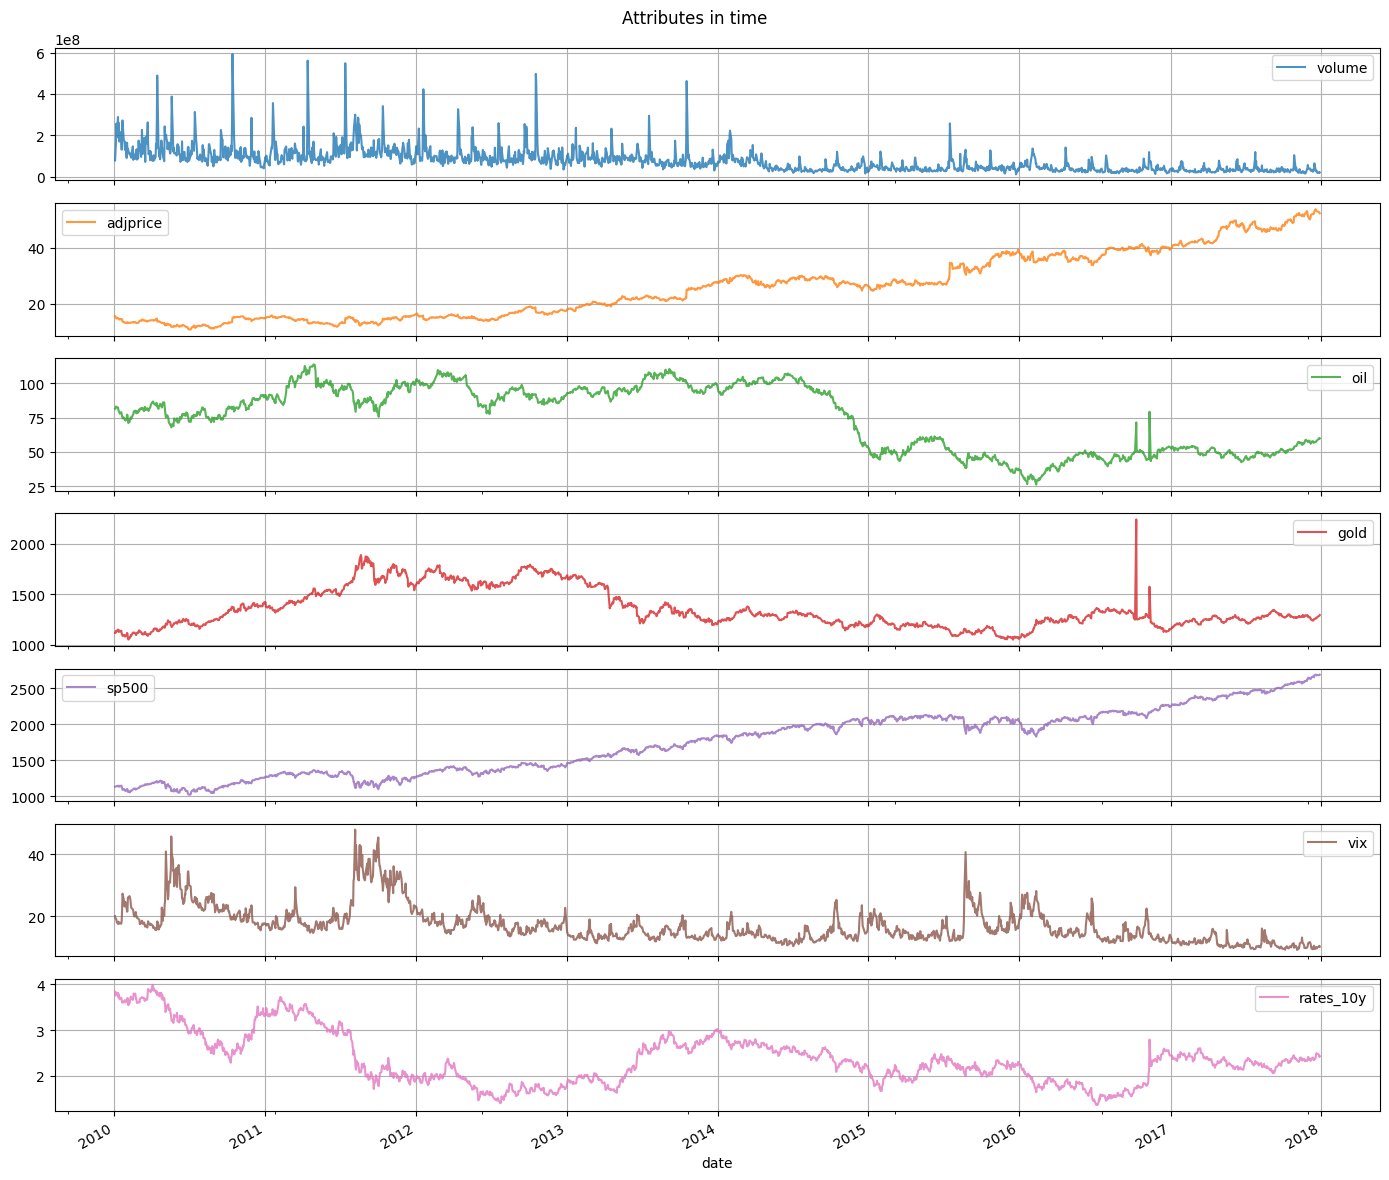

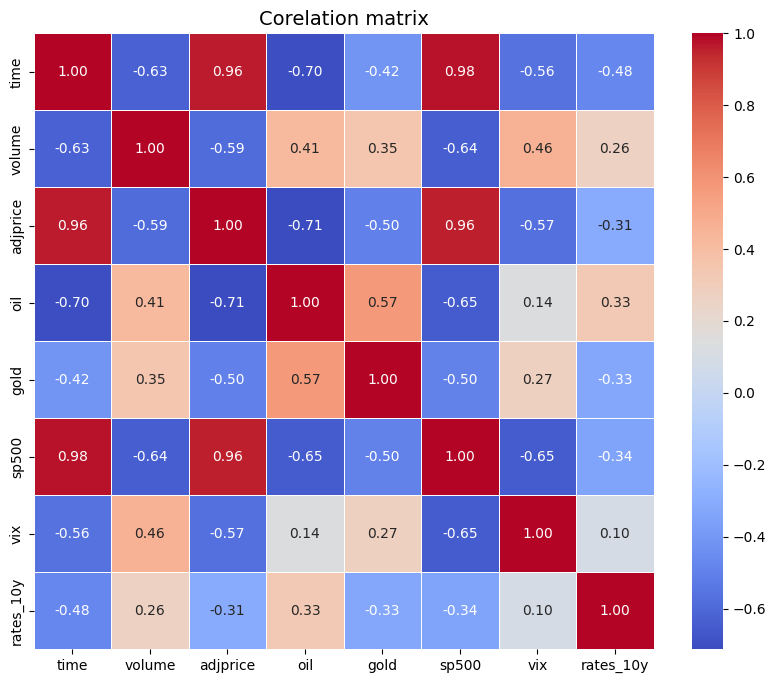

In [189]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1.
plt.figure(figsize=(14, 7))
plt.plot(df_final.index, df_final['adjprice'], label='Adjprice', color='royalblue', alpha=0.7)
plt.plot(df_final.index, df_final['adjprice'].rolling(window=30).mean(), label='Moving average (30 days)', color='orange', linewidth=2)
plt.plot(df_final.index, df_final['adjprice'].rolling(window=100).mean(), label='Moving average (100 days)', color='red', linewidth=2)
plt.title('Price in time with moving averages', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

# 2.
cols_to_plot = [col for col in df_final.columns if col != 'time']
df_final[cols_to_plot].plot(subplots=True, figsize=(14, 12), title="Attributes in time", grid=True, alpha=0.8)
plt.tight_layout()
plt.show()

# 3.
plt.figure(figsize=(10, 8))
sns.heatmap(df_final.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Corelation matrix', fontsize=14)
plt.show()


Splitting the data

Total samples: 2012
Training samples:   1408 (approx. 70%)
Validation samples: 302 (approx. 15%)
Test samples:       302 (approx. 15%)


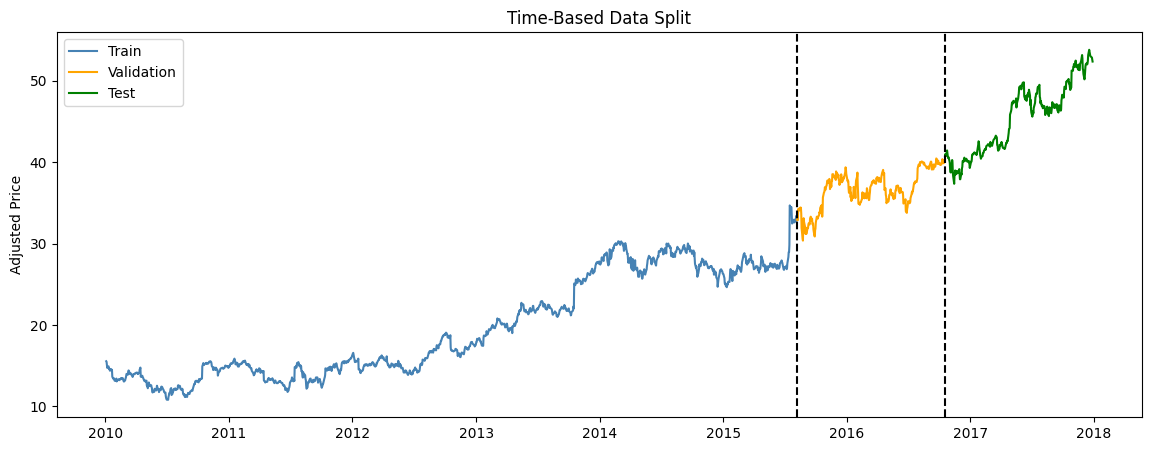

In [190]:
import matplotlib.pyplot as plt

X = df_final[['adjprice']].copy()
y = df_final['adjprice'].copy()

n = len(X)
train_end = int(n*0.7)
val_end = int(n*0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print(f"Total samples: {n}")
print(f"Training samples:   {len(X_train)} (approx. 70%)")
print(f"Validation samples: {len(X_val)} (approx. 15%)")
print(f"Test samples:       {len(X_test)} (approx. 15%)")


# ------------------------------------------------------------------ VISUALS
plt.figure(figsize=(14, 5))

dates = X.index

plt.plot(dates[:train_end], y_train, label='Train', color='steelblue')
plt.plot(dates[train_end:val_end], y_val, label='Validation', color='orange')
plt.plot(dates[val_end:], y_test, label='Test', color='green')

plt.axvline(dates[train_end], color='black', linestyle='--')
plt.axvline(dates[val_end], color='black', linestyle='--')

plt.title("Time-Based Data Split")
plt.ylabel("Adjusted Price")
plt.legend()
plt.show()

Because the original data was split for train, val and test datasets in quite an unfortunate places (those subsets had visibly different features) I have decided to conduct some experiments on a more consistant part of the data - first half of it.

#2. MODELS
* persistence model
* linear model
* neural model (FFNN)

Variants:
1. autoregressive (AR)
2. autoreggressive with exogenous inputs (ARX)






##**Persistence model**



Scores:
RMSE: 0.4362
MAE: 0.3137


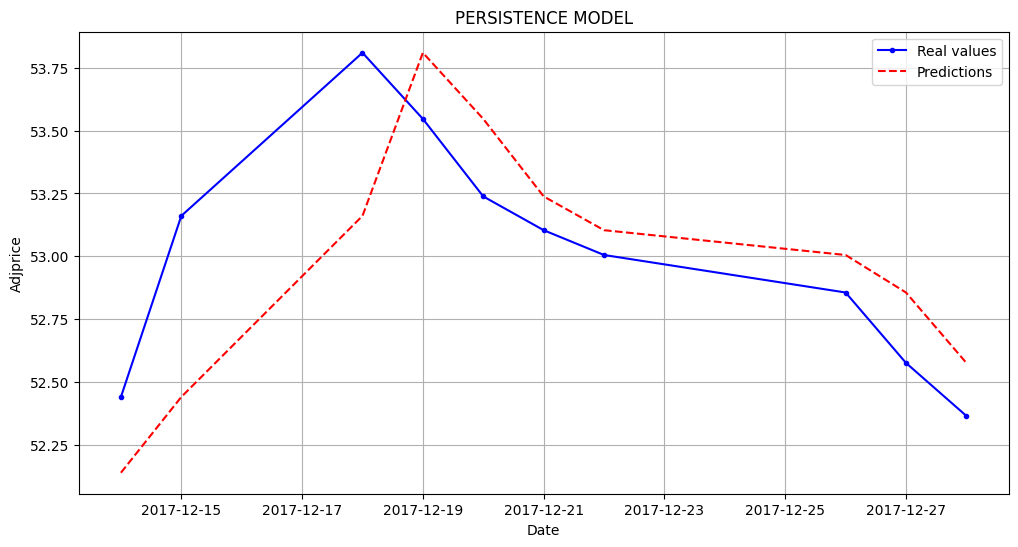

In [192]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

ts_data = df_final['adjprice']

split_index = int(len(ts_data) * 0.8)
train = ts_data.iloc[:split_index]
test = ts_data.iloc[split_index:]


persistence_predictions = pd.concat([train.iloc[-1:], test.iloc[:-1]]).values



# mse = 1/n sum {(y-y_pred)^2}
rmse = np.sqrt(mean_squared_error(test, persistence_predictions))
# mae = 1/n sum {y-y_pred}
mae = mean_absolute_error(test, persistence_predictions)

print(f"\nScores:")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")




# ------------------------------------------------------------------ VISUALS
nod = 10
plt.figure(figsize=(12, 6))
plt.plot(test.index[-nod:], test.values[-nod:], label='Real values', color='blue', marker='.')
plt.plot(test.index[-nod:], persistence_predictions[-nod:], label='Predictions', color='red', linestyle='--')

plt.title('PERSISTENCE MODEL')
plt.xlabel('Date')
plt.ylabel('Adjprice')
plt.legend()
plt.grid(True)
plt.show()



> The difference might be caused by the weekends and celebrations



##**Linear model**
1) AR

Tested lags= 1 | RMSE: 0.5164 | MAE: 0.3703
Tested lags= 2 | RMSE: 0.5166 | MAE: 0.3709
Tested lags= 3 | RMSE: 0.5166 | MAE: 0.3708
Tested lags= 5 | RMSE: 0.5172 | MAE: 0.3714
Tested lags=10 | RMSE: 0.5142 | MAE: 0.3698
Tested lags=15 | RMSE: 0.5147 | MAE: 0.3713
Tested lags=20 | RMSE: 0.5159 | MAE: 0.3730

best lags = 10
Score (AR, lags =10):
RMSE: 0.4564
MAE:  0.3323

Weights:
lag_1 (t-1): 1.0156
lag_2 (t-2): -0.0121
lag_3 (t-3): 0.0063
lag_4 (t-4): -0.0148
lag_5 (t-5): -0.0273
lag_6 (t-6): 0.0389
lag_7 (t-7): -0.0378
lag_8 (t-8): 0.0061
lag_9 (t-9): 0.0298
lag_10 (t-10): -0.0043


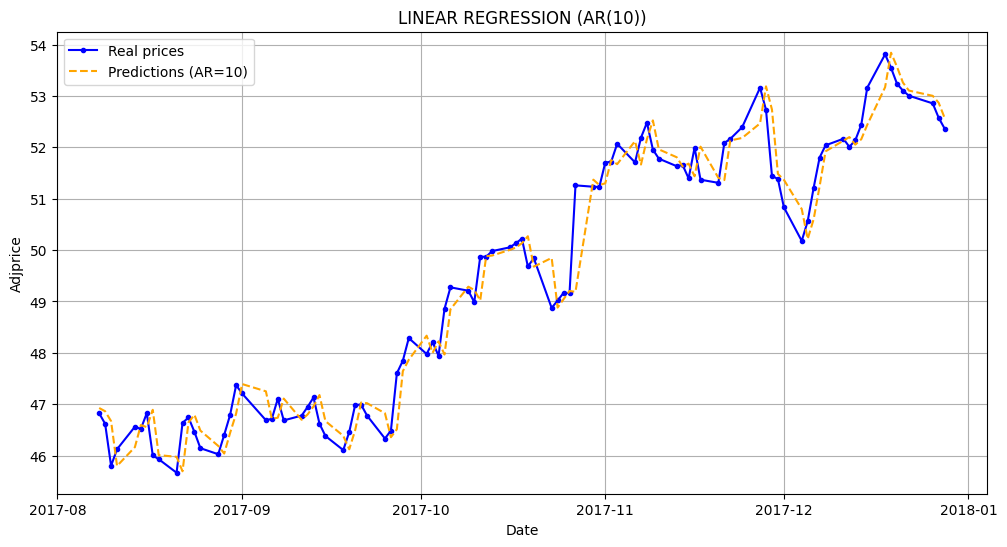

In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error


lags_grid = [1, 2, 3, 5, 10, 15, 20]

best_lag = None
best_rmse = float('inf')
best_mae = float('inf')
best_model = None
ar_y_test = None
best_x_test = None
best_predictions = None

for lags in lags_grid:
  df_ar = df_final[['adjprice']].copy()


  for i in range(1, lags + 1):
      df_ar[f'lag_{i}'] = df_ar['adjprice'].shift(i)

  df_ar = df_ar.dropna()

  X = df_ar.drop(columns=['adjprice'])
  y = df_ar['adjprice']



  n = len(df_ar)
  train_end = int(n*0.7)
  val_end = int(n*0.85)

  X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
  X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
  X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]


  lr_model = LinearRegression()
  lr_model.fit(X_train, y_train)

  lr_predictions = lr_model.predict(X_val)


  lr_rmse = np.sqrt(mean_squared_error(y_val, lr_predictions))
  lr_mae = mean_absolute_error(y_val, lr_predictions)


  print(f"Tested lags={lags:2d} | RMSE: {lr_rmse:.4f} | MAE: {lr_mae:.4f}")


  if lr_rmse < best_rmse:
      best_rmse = lr_rmse
      best_mae = lr_mae
      best_lag = lags
      best_model = lr_model
      best_x_test = X_test
      ar_y_test = y_test
      best_predictions = lr_predictions





lr_predictions = best_model.predict(best_x_test)
lr_rmse = np.sqrt(mean_squared_error(ar_y_test, lr_predictions))
lr_mae = mean_absolute_error(ar_y_test, lr_predictions)


# ------------------------------------------------------------------ VISUALS
print("\n" + "="*50)
print(f"best lags = {best_lag}")
print("="*50)
print(f"Score (AR, lags ={best_lag}):")
print(f"RMSE: {lr_rmse:.4f}")
print(f"MAE:  {lr_mae:.4f}")


print("\nWeights:")
for i, coef in enumerate(best_model.coef_, 1):
    print(f"lag_{i} (t-{i}): {coef:.4f}")


nod = 100
plt.figure(figsize=(12, 6))


plt.plot(ar_y_test.index[-nod:], ar_y_test.values[-nod:], label='Real prices', color='blue', marker='.')
plt.plot(ar_y_test.index[-nod:], lr_predictions[-nod:], label=f'Predictions (AR={best_lag})', color='orange', linestyle='--')

plt.title(f'LINEAR REGRESSION (AR({best_lag}))')
plt.xlabel('Date')
plt.ylabel('Adjprice')
plt.legend()
plt.grid(True)
plt.show()

2. ARX

Tests lags= 1 | RMSE: 0.5270 | MAE: 0.3843
Tests lags= 2 | RMSE: 0.5317 | MAE: 0.3898
Tests lags= 3 | RMSE: 0.5346 | MAE: 0.3918
Tests lags= 5 | RMSE: 0.5395 | MAE: 0.3947
Tests lags=10 | RMSE: 0.5414 | MAE: 0.3874


/tmp/ipykernel_1114/106261841.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_arx[f'{col}_lag_{i}'] = df_arx[col].shift(i)
/tmp/ipykernel_1114/106261841.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_arx[f'{col}_lag_{i}'] = df_arx[col].shift(i)
/tmp/ipykernel_1114/106261841.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragme

Tests lags=15 | RMSE: 0.5515 | MAE: 0.3994


/tmp/ipykernel_1114/106261841.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_arx[f'{col}_lag_{i}'] = df_arx[col].shift(i)
/tmp/ipykernel_1114/106261841.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_arx[f'{col}_lag_{i}'] = df_arx[col].shift(i)
/tmp/ipykernel_1114/106261841.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragme

Tests lags=20 | RMSE: 0.5626 | MAE: 0.4094

best lags = 1
Score (ARX, lags =1):
RMSE: 0.4949
MAE:  0.3749

Weights:
adjprice_lag_1: 0.986155
volume_lag_1: 0.000000
oil_lag_1: 0.000956
gold_lag_1: -0.000141
sp500_lag_1: 0.000247
vix_lag_1: 0.000996
rates_10y_lag_1: -0.045407


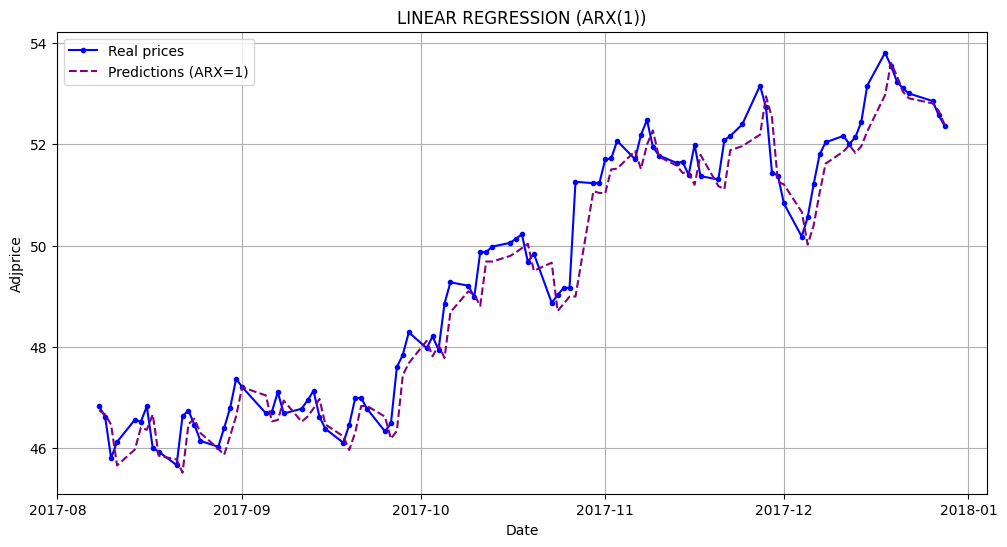

In [177]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error



lags_grid = [1, 2, 3, 5, 10, 15, 20]

best_lag = None
best_rmse = float('inf')
best_mae = float('inf')
best_model = None
best_x_test = None
arx_y_test = None
best_predictions = None
best_x_columns = None


target_col = 'adjprice'
exogenous_cols = ['volume', 'oil', 'gold', 'sp500', 'vix', 'rates_10y']


for lags in lags_grid:
  df_arx = df_final[[target_col] + exogenous_cols].copy()


  for col in [target_col] + exogenous_cols:
        for i in range(1, lags + 1):
            df_arx[f'{col}_lag_{i}'] = df_arx[col].shift(i)



  df_arx = df_arx.drop(columns=exogenous_cols)
  df_arx = df_arx.dropna()


  X = df_arx.drop(columns=[target_col])
  y = df_arx[target_col]


  n = len(df_arx)
  train_end = int(n*0.7)
  val_end = int(n*0.85)

  X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
  X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
  X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]




  arx_model = LinearRegression()
  arx_model.fit(X_train, y_train)

  arx_predictions = arx_model.predict(X_val)
  arx_rmse = np.sqrt(mean_squared_error(y_val, arx_predictions))
  arx_mae = mean_absolute_error(y_val, arx_predictions)


  print(f"Tests lags={lags:2d} | RMSE: {arx_rmse:.4f} | MAE: {arx_mae:.4f}")


  if arx_rmse < best_rmse:
      best_rmse = arx_rmse
      best_mae = arx_mae
      best_lag = lags
      best_model = arx_model

      best_x_test = X_test
      arx_y_test = y_test
      best_x_columns = X.columns





final_predictions = best_model.predict(best_x_test)
final_rmse = np.sqrt(mean_squared_error(arx_y_test, final_predictions))
final_mae = mean_absolute_error(arx_y_test, final_predictions)





print("\n" + "="*50)
print(f"best lags = {best_lag}")
print("="*50)
print(f"Score (ARX, lags ={best_lag}):")
print(f"RMSE: {final_rmse:.4f}")
print(f"MAE:  {final_mae:.4f}")





print("\nWeights:")
for feature, coef in zip(best_x_columns, best_model.coef_):
    print(f"{feature}: {coef:.6f}")






# ------------------------------------------------------------------ VISUALS
plt.figure(figsize=(12, 6))
plt.plot(arx_y_test.index[-100:], arx_y_test.values[-100:], label='Real prices', color='blue', marker='.')
plt.plot(arx_y_test.index[-100:], final_predictions[-100:], label=f'Predictions (ARX={best_lag})', color='purple', linestyle='--')

plt.title(f'LINEAR REGRESSION (ARX({best_lag}))')
plt.xlabel('Date')
plt.ylabel('Adjprice')
plt.legend()
plt.grid(True)
plt.show()

##FFNN
1. AR on differences

Used device: cpu
Tested params: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 16} | Best Val Loss: 2.5988
Tested params: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 32} | Best Val Loss: 2.6053
Tested params: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 64} | Best Val Loss: 2.5827
Tested params: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 16} | Best Val Loss: 2.5864
Tested params: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 32} | Best Val Loss: 2.5827
Tested params: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 64} | Best Val Loss: 2.5863
Tested params: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 16} | Best Val Loss: 2.4905
Tested params: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 32} | Best Val Loss: 2.4926
Tested params: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 64} | Best Val Loss: 2.4895
Tested params: {'batch_size': 32, 'lr': 0.005, 'hidden_dim': 16} | Best Val Loss: 2.4932
Tested params: {'batch_size': 32, 'lr': 0.005, 'hidden_dim': 32} | Best Val Loss: 2.4898
Test

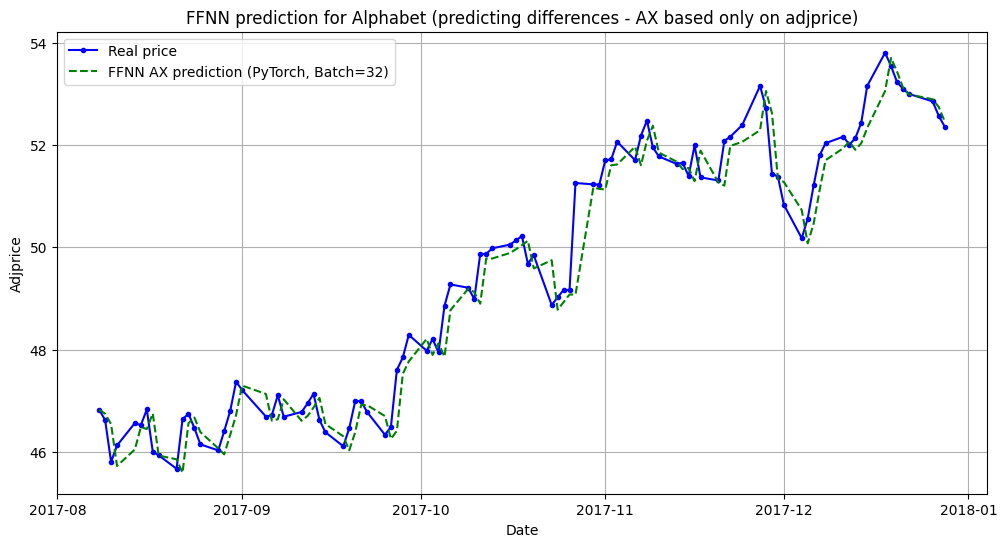

In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import itertools

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

def set_reproducibility(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_reproducibility(42)



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Used device: {device}")

target_col = 'adjprice'
lags = 5



df_ffnn = df_final[[target_col]].copy()

for i in range(1, lags + 1):
    df_ffnn[f'{target_col}_lag_{i}'] = df_ffnn[target_col].shift(i)



df_ffnn['target_diff'] = df_ffnn['adjprice'] - df_ffnn['adjprice_lag_1']


df_ffnn = df_ffnn.dropna()



X = df_ffnn.drop(columns=[target_col, 'target_diff'])
y = df_ffnn['target_diff']

n = len(df_ffnn)
train_end = int(n*0.7)
val_end = int(n*0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32).to(device)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32).to(device)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)

# ------------------------------------------------------------------ GRID SEARCH
param_grid = {
    'batch_size': [16, 32, 64],
    'lr': [0.001, 0.005],
    'hidden_dim': [16, 32, 64]
}

keys, values = zip(*param_grid.items())
hyperparameter_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_overall_val_loss = float('inf')
best_model_state = None
best_params = None
epochs = 100
patience = 10



for params in hyperparameter_combinations:
    batch_size = params['batch_size']
    lr = params['lr']
    hidden_dim = params['hidden_dim']

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataset = TensorDataset(X_val_t, y_val_t)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = nn.Sequential(
        nn.Linear(X_train_t.shape[1], hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim // 2),
        nn.ReLU(),
        nn.Linear(hidden_dim // 2, 1)
    ).to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_loss_current_model = float('inf')
    best_weights_current = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss_total = 0
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                val_preds = model(batch_X)
                batch_loss = criterion(val_preds, batch_y)
                val_loss_total += batch_loss.item()

        val_loss_avg = val_loss_total / len(val_loader)

        if val_loss_avg < best_val_loss_current_model:
            best_val_loss_current_model = val_loss_avg
            best_weights_current = model.state_dict()
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    print(f"Tested params: {params} | Best Val Loss: {best_val_loss_current_model:.4f}")

    if best_val_loss_current_model < best_overall_val_loss:
        best_overall_val_loss = best_val_loss_current_model
        best_model_state = best_weights_current
        best_params = params

print("\n" + "="*50)
print(f"BEST PARAMS FFNN (AR): {best_params}")
print("="*50)

best_model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], best_params['hidden_dim']),
    nn.ReLU(),
    nn.Linear(best_params['hidden_dim'], best_params['hidden_dim'] // 2),
    nn.ReLU(),
    nn.Linear(best_params['hidden_dim'] // 2, 1)
).to(device)
best_model.load_state_dict(best_model_state)

# ------------------------------------------------------------------ RECONSTRUCTION AND VALIDATION
best_model.eval()
with torch.no_grad():
    predicted_diff_scaled = best_model(X_test_t).cpu().numpy()

predicted_diff_ax = scaler_y.inverse_transform(predicted_diff_scaled).flatten()
ffnn_ax_predictions = X_test['adjprice_lag_1'].values + predicted_diff_ax

real_prices_test_ax = df_final.loc[X_test.index, target_col]

ffnn_ax_rmse = np.sqrt(mean_squared_error(real_prices_test_ax, ffnn_ax_predictions))
ffnn_ax_mae = mean_absolute_error(real_prices_test_ax, ffnn_ax_predictions)

print("\nActual results on the test set (best FFNN AX model):")
print(f"RMSE: {ffnn_ax_rmse:.4f}")
print(f"MAE:  {ffnn_ax_mae:.4f}")

# ------------------------------------------------------------------ VISUALS
plt.figure(figsize=(12, 6))
plt.plot(real_prices_test_ax.index[-100:], real_prices_test_ax.values[-100:], label='Real price', color='blue', marker='.')
plt.plot(real_prices_test_ax.index[-100:], ffnn_ax_predictions[-100:], label=f"FFNN AX prediction (PyTorch, Batch={best_params['batch_size']})", color='green', linestyle='--')

plt.title('FFNN prediction for Alphabet (predicting differences - AX based only on adjprice)')
plt.xlabel('Date')
plt.ylabel('Adjprice')
plt.legend()
plt.grid(True)
plt.show()

2. ARX on differences

Used device: cpu
Starting Grid Search (18 combinations)...
Tested parameters: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 16} | Best Val Loss: 2.5851
Tested parameters: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 32} | Best Val Loss: 2.5774
Tested parameters: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 64} | Best Val Loss: 2.5767
Tested parameters: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 16} | Best Val Loss: 2.5863
Tested parameters: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 32} | Best Val Loss: 2.5843
Tested parameters: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 64} | Best Val Loss: 2.5807
Tested parameters: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 16} | Best Val Loss: 2.4843
Tested parameters: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 32} | Best Val Loss: 2.4941
Tested parameters: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 64} | Best Val Loss: 2.4938
Tested parameters: {'batch_size': 32, 'lr': 0.005, 'hidden_dim': 16} | Best Val Loss: 2.4824
Tested para

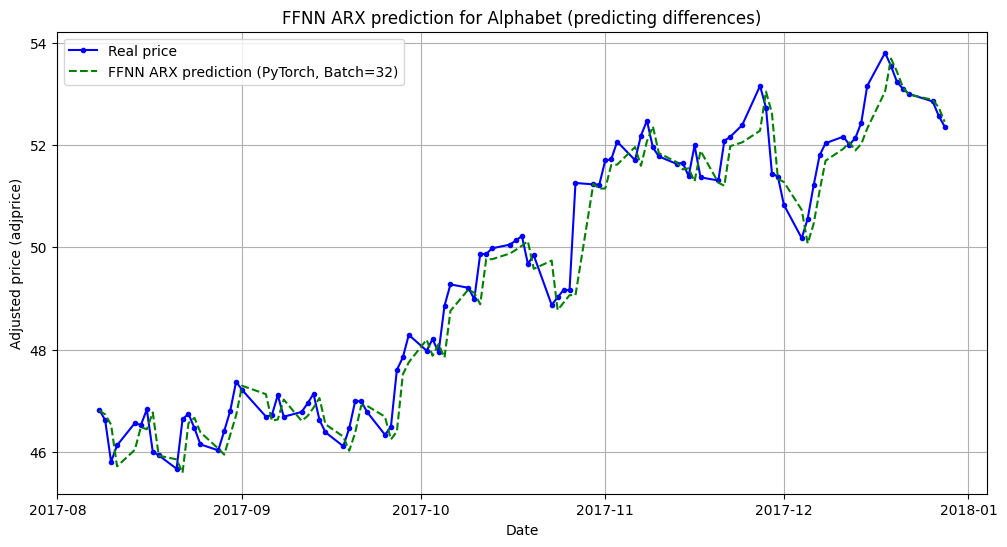

In [179]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import itertools

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

def set_reproducibility(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_reproducibility(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Used device: {device}")

target_col = 'adjprice'
exogenous_cols = ['volume', 'oil', 'gold', 'sp500', 'vix', 'rates_10y']
lags = 5

df_ffnn = df_final[[target_col] + exogenous_cols].copy()

for col in [target_col] + exogenous_cols:
    for i in range(1, lags + 1):
        df_ffnn[f'{col}_lag_{i}'] = df_ffnn[col].shift(i)


df_ffnn['target_diff'] = df_ffnn['adjprice'] - df_ffnn['adjprice_lag_1']

df_ffnn = df_ffnn.drop(columns=exogenous_cols)
df_ffnn = df_ffnn.dropna()

X = df_ffnn.drop(columns=[target_col, 'target_diff'])
y = df_ffnn['target_diff']

n = len(df_ffnn)
train_end = int(n*0.7)
val_end = int(n*0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32).to(device)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32).to(device)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)

# ------------------------------------------------------------------ GRID SEARCH
param_grid = {
    'batch_size': [16, 32, 64],
    'lr': [0.001, 0.005],
    'hidden_dim': [16, 32, 64]
}

keys, values = zip(*param_grid.items())
hyperparameter_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_overall_val_loss = float('inf')
best_model_state = None
best_params = None
epochs = 100
patience = 10

print(f"Starting Grid Search ({len(hyperparameter_combinations)} combinations)...")

for params in hyperparameter_combinations:
    batch_size = params['batch_size']
    lr = params['lr']
    hidden_dim = params['hidden_dim']

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataset = TensorDataset(X_val_t, y_val_t)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = nn.Sequential(
        nn.Linear(X_train_t.shape[1], hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim // 2),
        nn.ReLU(),
        nn.Linear(hidden_dim // 2, 1)
    ).to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_loss_current_model = float('inf')
    best_weights_current = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss_total = 0
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                val_preds = model(batch_X)
                batch_loss = criterion(val_preds, batch_y)
                val_loss_total += batch_loss.item()

        val_loss_avg = val_loss_total / len(val_loader)

        if val_loss_avg < best_val_loss_current_model:
            best_val_loss_current_model = val_loss_avg
            best_weights_current = model.state_dict()
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    print(f"Tested parameters: {params} | Best Val Loss: {best_val_loss_current_model:.4f}")

    if best_val_loss_current_model < best_overall_val_loss:
        best_overall_val_loss = best_val_loss_current_model
        best_model_state = best_weights_current
        best_params = params

print("\n" + "="*50)
print(f"BEST PARAMS FFNN (PyTorch, ARX): {best_params}")
print("="*50)

best_model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], best_params['hidden_dim']),
    nn.ReLU(),
    nn.Linear(best_params['hidden_dim'], best_params['hidden_dim'] // 2),
    nn.ReLU(),
    nn.Linear(best_params['hidden_dim'] // 2, 1)
).to(device)
best_model.load_state_dict(best_model_state)

# ------------------------------------------------------------------ RECONSTRUCTION AND VALIDATION
best_model.eval()
with torch.no_grad():
    predicted_diff_scaled = best_model(X_test_t).cpu().numpy()

predicted_diff_arx = scaler_y.inverse_transform(predicted_diff_scaled).flatten()
ffnn_arx_diff_predictions = X_test['adjprice_lag_1'].values + predicted_diff_arx

real_prices_test_arx = df_final.loc[X_test.index, target_col]

ffnn_arx_diff_rmse = np.sqrt(mean_squared_error(real_prices_test_arx, ffnn_arx_diff_predictions))
ffnn_arx_diff_mae = mean_absolute_error(real_prices_test_arx, ffnn_arx_diff_predictions)

print("\nActual results on the test set (best FFNN ARX Diff model):")
print(f"RMSE: {ffnn_arx_diff_rmse:.4f}")
print(f"MAE:  {ffnn_arx_diff_mae:.4f}")

# ------------------------------------------------------------------ VISUALS
plt.figure(figsize=(12, 6))
plt.plot(real_prices_test_arx.index[-100:], real_prices_test_arx.values[-100:], label='Real price', color='blue', marker='.')
plt.plot(real_prices_test_arx.index[-100:], ffnn_arx_diff_predictions[-100:], label=f"FFNN ARX prediction (PyTorch, Batch={best_params['batch_size']})", color='green', linestyle='--')

plt.title('FFNN ARX prediction for Alphabet (predicting differences)')
plt.xlabel('Date')
plt.ylabel('Adjusted price (adjprice)')
plt.legend()
plt.grid(True)
plt.show()

Predicted values vs real comparison




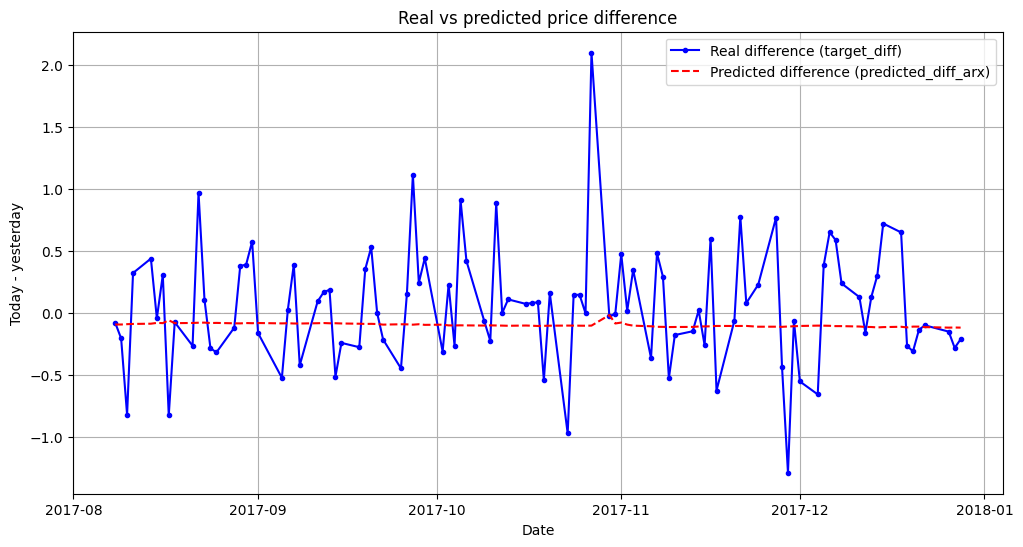

In [180]:
import matplotlib.pyplot as plt
import pandas as pd


actual_prices = df_final['adjprice']
actual_diff_full = actual_prices.diff().dropna()

actual_diff = actual_diff_full.loc[X_test.index]


nod = 100

plt.figure(figsize=(12, 6))
plt.plot(actual_diff.index[-nod:], actual_diff.values[-nod:], label='Real difference (target_diff)', color='blue', marker='.')
plt.plot(actual_diff.index[-nod:], predicted_diff_arx[-nod:], label='Predicted difference (predicted_diff_arx)', color='red', linestyle='--')

plt.title('Real vs predicted price difference')
plt.xlabel('Date')
plt.ylabel('Today - yesterday')
plt.legend()
plt.grid(True)
plt.show()

3. ARX on prices

Used device: cpu
Starting Grid Search (18 combinations)...
Tested parameters: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 16} | Best Val Loss: 0.0143
Tested parameters: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 32} | Best Val Loss: 0.0424
Tested parameters: {'batch_size': 16, 'lr': 0.001, 'hidden_dim': 64} | Best Val Loss: 0.0253
Tested parameters: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 16} | Best Val Loss: 0.0121
Tested parameters: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 32} | Best Val Loss: 0.0345
Tested parameters: {'batch_size': 16, 'lr': 0.005, 'hidden_dim': 64} | Best Val Loss: 0.0152
Tested parameters: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 16} | Best Val Loss: 0.0427
Tested parameters: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 32} | Best Val Loss: 0.0910
Tested parameters: {'batch_size': 32, 'lr': 0.001, 'hidden_dim': 64} | Best Val Loss: 0.0574
Tested parameters: {'batch_size': 32, 'lr': 0.005, 'hidden_dim': 16} | Best Val Loss: 0.0109
Tested para

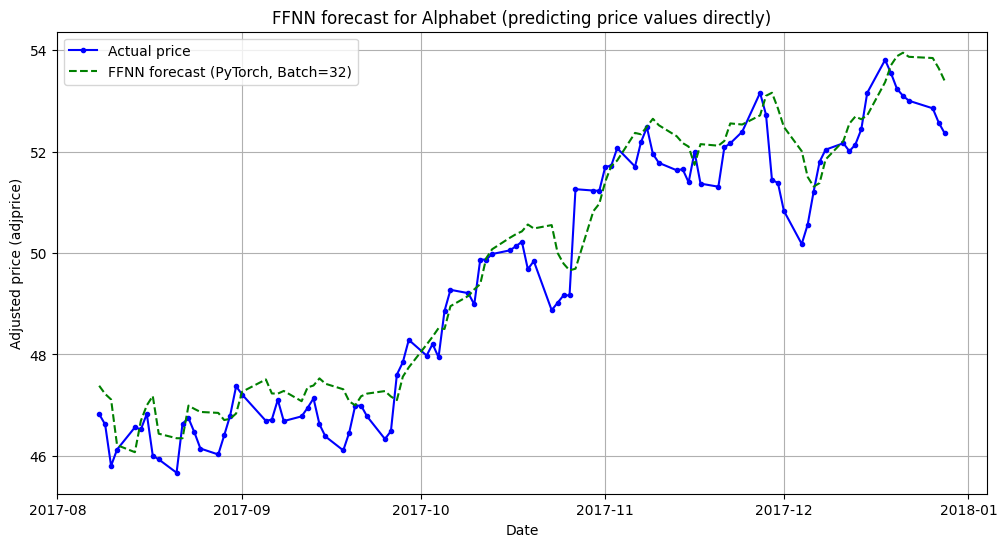

In [181]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import itertools

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy


def set_reproducibility(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_reproducibility(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Used device: {device}")

target_col = 'adjprice'
exogenous_cols = ['volume', 'oil', 'gold', 'sp500', 'vix', 'rates_10y']
lags = 5

df_ffnn = df_final[[target_col] + exogenous_cols].copy()

for col in [target_col] + exogenous_cols:
    for i in range(1, lags + 1):
        df_ffnn[f'{col}_lag_{i}'] = df_ffnn[col].shift(i)



df_ffnn = df_ffnn.drop(columns=exogenous_cols)
df_ffnn = df_ffnn.dropna()

X = df_ffnn.drop(columns=[target_col])
y = df_ffnn[target_col]

n = len(df_ffnn)
train_end = int(n*0.7)
val_end = int(n*0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32).to(device)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32).to(device)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)

# ------------------------------------------------------------------ GRID SEARCH
param_grid = {
    'batch_size': [16, 32, 64],
    'lr': [0.001, 0.005],
    'hidden_dim': [16, 32, 64]
}

keys, values = zip(*param_grid.items())
hyperparameter_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_overall_val_loss = float('inf')
best_model_state = None
best_params = None
epochs = 100
patience = 10

print(f"Starting Grid Search ({len(hyperparameter_combinations)} combinations)...")

for params in hyperparameter_combinations:
    batch_size = params['batch_size']
    lr = params['lr']
    hidden_dim = params['hidden_dim']

    train_dataset = TensorDataset(X_train_t, y_train_t)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataset = TensorDataset(X_val_t, y_val_t)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = nn.Sequential(
        nn.Linear(X_train_t.shape[1], hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, hidden_dim // 2),
        nn.ReLU(),
        nn.Linear(hidden_dim // 2, 1)
    ).to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_loss_current_model = float('inf')
    best_weights_current = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss_total = 0
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                val_preds = model(batch_X)
                batch_loss = criterion(val_preds, batch_y)
                val_loss_total += batch_loss.item()

        val_loss_avg = val_loss_total / len(val_loader)


        if val_loss_avg < best_val_loss_current_model:
          best_val_loss_current_model = val_loss_avg
          best_weights_current = copy.deepcopy(model.state_dict())
          patience_counter = 0



        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    print(f"Tested parameters: {params} | Best Val Loss: {best_val_loss_current_model:.4f}")

    if best_val_loss_current_model < best_overall_val_loss:
        best_overall_val_loss = best_val_loss_current_model
        best_model_state = best_weights_current
        best_params = params




print("\n" + "="*50)
print(f"BEST PARAMS FFNN (PyTorch): {best_params}")
print("="*50)



best_model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], best_params['hidden_dim']),
    nn.ReLU(),
    nn.Linear(best_params['hidden_dim'], best_params['hidden_dim'] // 2),
    nn.ReLU(),
    nn.Linear(best_params['hidden_dim'] // 2, 1)
).to(device)
best_model.load_state_dict(best_model_state)

# ------------------------------------------------------------------ VALIDATION
best_model.eval()
with torch.no_grad():
    ffnn_predictions_scaled = best_model(X_test_t).cpu().numpy()

ffnn_predictions = scaler_y.inverse_transform(ffnn_predictions_scaled).flatten()

real_prices_test = df_final.loc[X_test.index, target_col]

ffnn_rmse = np.sqrt(mean_squared_error(real_prices_test, ffnn_predictions))
ffnn_mae = mean_absolute_error(real_prices_test, ffnn_predictions)

print("\nActual results on the test set (best model):")
print(f"RMSE: {ffnn_rmse:.4f}")
print(f"MAE:  {ffnn_mae:.4f}")

# ------------------------------------------------------------------ VISUALS
plt.figure(figsize=(12, 6))
plt.plot(real_prices_test.index[-100:], real_prices_test.values[-100:], label='Actual price', color='blue', marker='.')
plt.plot(real_prices_test.index[-100:], ffnn_predictions[-100:], label=f"FFNN forecast (PyTorch, Batch={best_params['batch_size']})", color='green', linestyle='--')

plt.title('FFNN forecast for Alphabet (predicting price values directly)')
plt.xlabel('Date')
plt.ylabel('Adjusted price (adjprice)')
plt.legend()
plt.grid(True)
plt.show()

# SUMMARY

In [182]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate_forecast(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return {"Model": model_name, "RMSE": rmse, "MAE": mae}

performance_metrics = []

# 1. Persistence Model
res_persistence = evaluate_forecast(test, persistence_predictions, "Persistence (Naive)")
performance_metrics.append(res_persistence)

# 2. Linear AR Model
res_ar = evaluate_forecast(ar_y_test, lr_predictions, "Linear AR")
performance_metrics.append(res_ar)

# 3. Linear ARX Model
res_arx = evaluate_forecast(arx_y_test, final_predictions, "Linear ARX")
performance_metrics.append(res_arx)

# 4. FFNN AX differences
res_ffnn_ax = evaluate_forecast(real_prices_test_ax, ffnn_ax_predictions, "FFNN AX (diff)")
performance_metrics.append(res_ffnn_ax)

# 5. FFNN ARX differences
res_ffnn_arx_diff = evaluate_forecast(real_prices_test_arx, ffnn_arx_diff_predictions, "FFNN ARX (diff)")
performance_metrics.append(res_ffnn_arx_diff)

# 6. FFNN ARX Raw Prices
res_ffnn_prices = evaluate_forecast(real_prices_test, ffnn_predictions, "FFNN ARX prices")
performance_metrics.append(res_ffnn_prices)

df_metrics = pd.DataFrame(performance_metrics)
display(df_metrics)

,Model,RMSE,MAE
0,Persistence (Naive),0.436221,0.313737
1,Linear AR,0.456355,0.332314
2,Linear ARX,0.494888,0.374918
3,FFNN AX (diff),0.470774,0.347560
4,FFNN ARX (diff),0.473204,0.348308
5,FFNN ARX prices,0.713017,0.526549


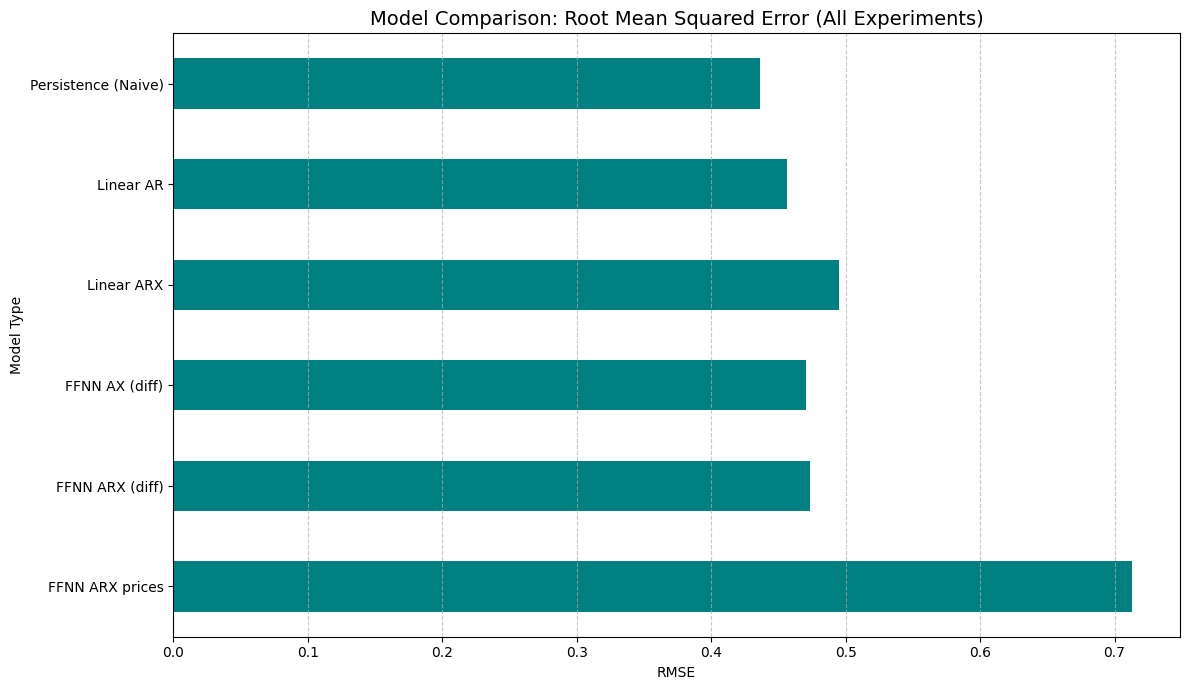

In [183]:
plt.figure(figsize=(12, 7))


df_metrics.set_index('Model')['RMSE'].plot(kind='barh', color='teal')
plt.gca().invert_yaxis()

plt.title("Model Comparison: Root Mean Squared Error (All Experiments)", fontsize=14)
plt.xlabel("RMSE")
plt.ylabel("Model Type")

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Comparison on the whole dataset

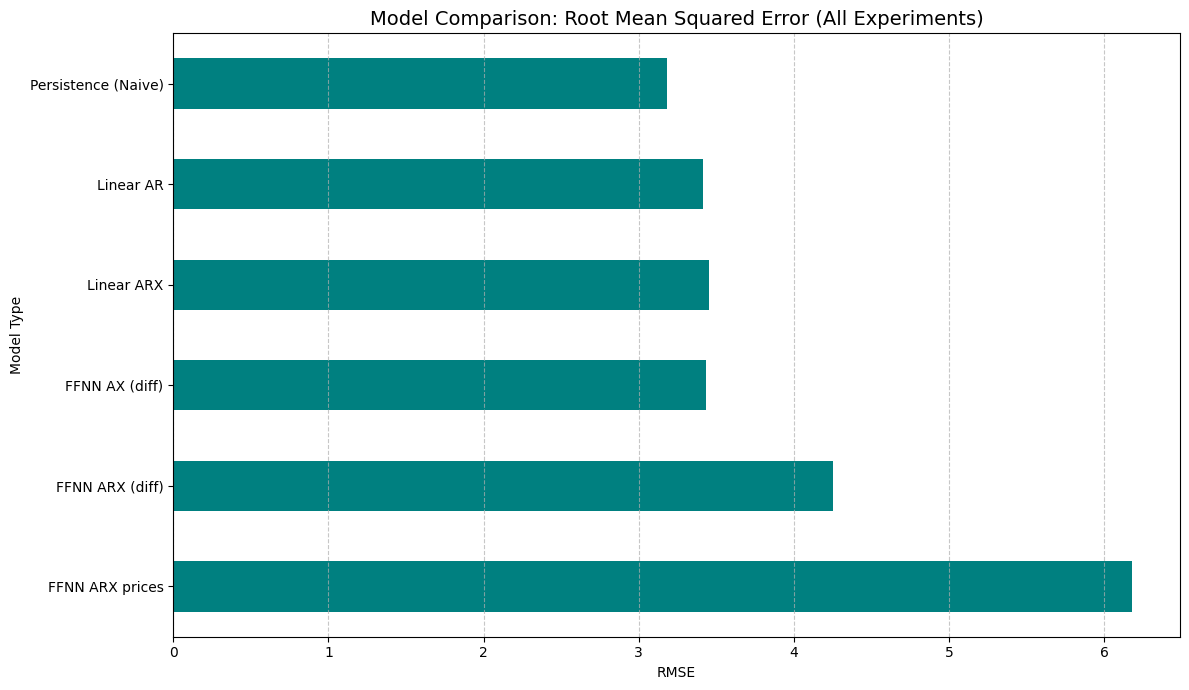

* Suprisingly, the best model for the data was the naive one. The reason for that could be the data itself with its irregularity.
* Looking at the neural networks - the worst model of all was the FFNN predicting the whole prices. That is because NNs in general have trouble predicting in ranges outside those they was trained on. That is also why networks built on price differences between days thrived.
* Comparing the results on the half of the dataset to those on the full one - cutting the fluctuations, even though it wouldn't work on real life problem made the models work almost 10x better. That shows how important the data is and how financial data can be tricky to model.
